# 🪄 SAM 2.1 — Single Image Background Remover

Remove the background from **image** and replace it with another image using SAM 2.1.

### How it works
1. Upload your subject image and replacement background.
2. Give SAM 2.1 one point on the person/object you want to keep.
3. SAM 2.1 creates a segmentation mask.
4. Use the mask to place the subject on the new background.


## 1. Install the required libraries

In [ ]:
!pip install -q -U ultralytics opencv-python matplotlib

## 2. Import libraries

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from ultralytics import SAM

print("Libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Libraries imported successfully!


## 3. Create the images and background folder

In [ ]:
# Create the images folder.
os.makedirs("images", exist_ok=True)

# Create the background folder.
os.makedirs("background", exist_ok=True)


## 5. Choose a point on the subject 👆

Look at the input image above and enter a point that lies **inside the person/object**.

- `x` increases from left to right.
- `y` increases from top to bottom.
- The coordinate format is `[x, y]`.

Start with one positive point. You can add more points later if the mask needs improvement.

In [ ]:
# Change these coordinates to points inside your subject.
# x increases from left to right.
# y increases from top to bottom.
# Each point is represented as (x, y).


POINTS = {
    '01.jpg': [[(355, 299)]],
    '02.jpg': [
        [(228, 275)],
        [(220,391)],
        [(358,331)],
        [(220,66)]
    ],
    '03.jpg': [
        [(306, 354)],
        [(360,137)],
        [(424,357)],
        [(503,465)],
        [(140,320)]
    ],
    '04.jpg': [
        [(58,222)],
        [(173, 222)],
        [(300,222)],
        [(426,222)],
        [(562,222)],
        [(376,325)]
    ]
}


# Define labels corresponding to the selected points.
# 1 = Positive point (Foreground / Subject).
# 0 = Negative point (Background).
# Each point must have a corresponding label.

LABELS = {
    '01.jpg': [[1]],
    '02.jpg': [
        [1],
        [1],
        [1],
        [1]
    ],
    '03.jpg': [
        [1],
        [1],
        [1],
        [1],
        [1]
    ],
    '04.jpg': [
        [1],
        [1],
        [1],
        [1],
        [1],
        [1]
    ]
}


## 6. Load SAM 2.1 and generate the subject mask

The `sam2.1_t.pt` model is the Tiny version of SAM 2.1.

In [ ]:
# Original masks (shape = 2, 3, 3):

# Mask 1:             Mask 2:
# [[255, 0,   0],     [[0, 255, 0],
#  [  0, 0, 255],      [0,   0, 0],
#  [  0, 0,   0]]      [255, 0, 255]]


# axis=0: Combine both masks pixel by pixel.
# Result (3, 3):
# [[ True,  True, False],
#  [False, False,  True],
#  [ True, False,  True]]


# axis=1: Combine rows within each mask (vertically).
# Result (2, 3):
# [[ True, False,  True],   # Mask 1
#  [ True,  True,  True]]   # Mask 2


# axis=2: Combine columns within each mask (horizontally).
# Result (2, 3):
# [[ True,  True,  False],  # Mask 1
#  [ True, False,  True]]   # Mask 2

Mask without Shape: (5, 477, 850)
Mask Shape: (477, 850)
Image Shape: (477, 850, 3)


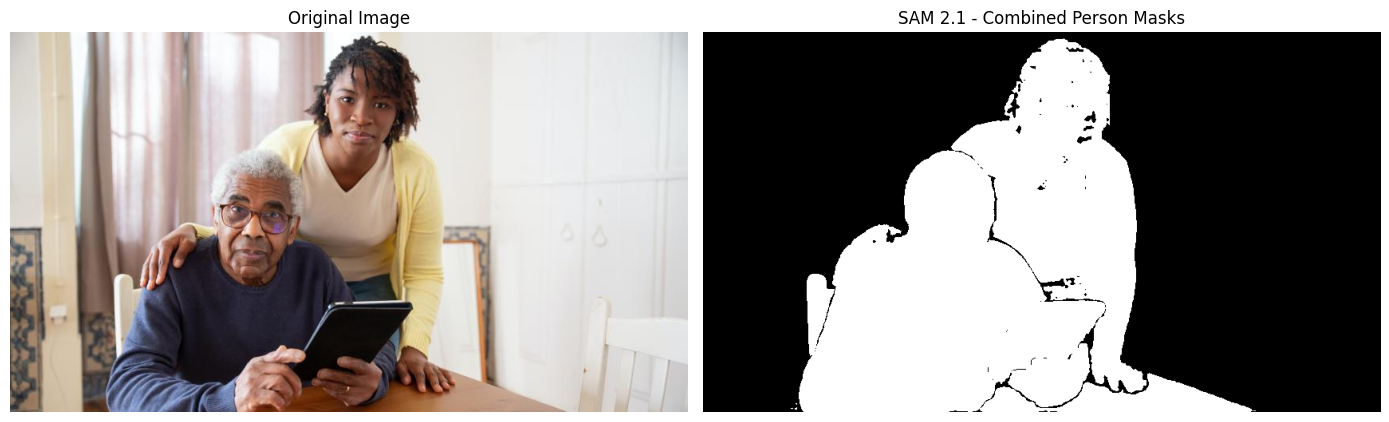

In [ ]:
# Load the original image.
img_path = '03.jpg'
image_path = f'images/{img_path}'

image = cv2.imread(image_path)

# Check whether image was loaded.
if image is None:
    raise RuntimeError("Image not found!")

# Convert BGR to RGB for Matplotlib.
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Get original image dimensions.
height, width = image.shape[:2]

# Load the SAM 2.1 model.
model = SAM("sam2.1_t.pt")

# Generate segmentation masks.
results = model.predict(
    source=image_path,
    points=POINTS[img_path],
    labels=LABELS[img_path],
    verbose=False
)

# Check whether masks were generated.
if results[0].masks is None:
    raise RuntimeError("SAM 2.1 did not return any masks.")

# Get all predicted masks.
masks = results[0].masks.data.cpu().numpy()

# Combine all person masks.
mask = np.any(masks > 0, axis=0).astype(np.uint8)

# Display image and mask shapes.
print("Mask without Shape:", masks.shape)
print("Mask Shape:", mask.shape)
print("Image Shape:", image_rgb.shape)

# Resize mask to original image dimensions, if required.
if mask.shape != (height, width):
    mask = cv2.resize(mask, (width, height))

# Display original image and combined mask.
plt.figure(figsize=(14, 6))

# Original image.
plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

# Combined segmentation mask.
plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("SAM 2.1 - Combined Person Masks")
plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Replace the background

The mask tells us which pixels belong to the subject.

- White / high mask values = keep the subject.
- Black / low mask values = replace with the new background.

We slightly smooth the mask edges to make the result look more natural.

Background replacement completed!


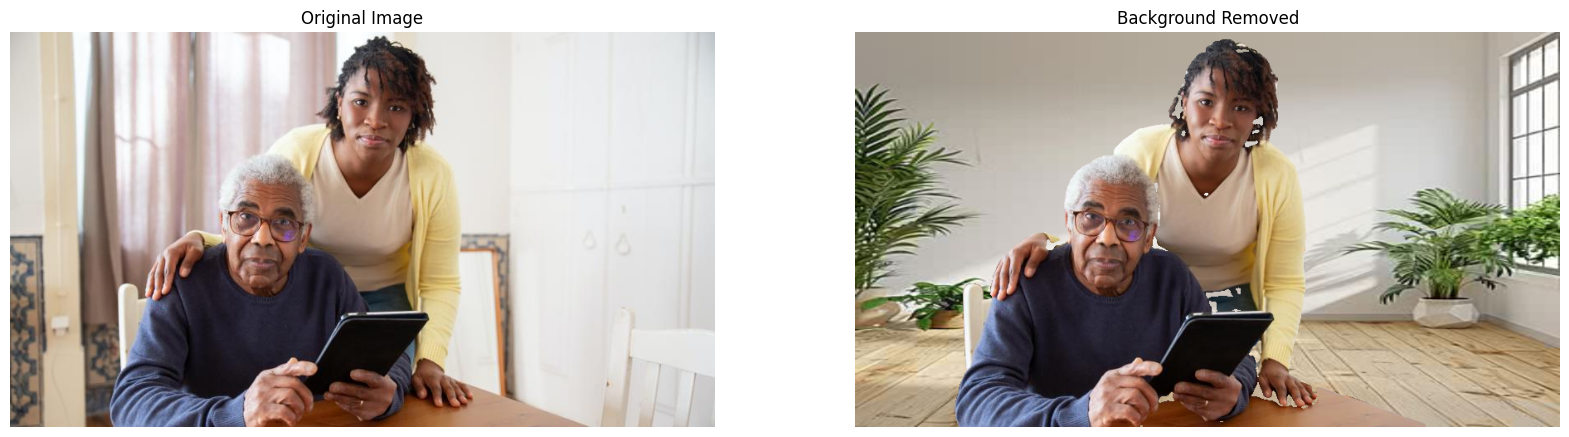

In [ ]:

# Load the new background image using OpenCV.
background = cv2.imread("background/background_03.jpg")

# Resize the background image to match the original image dimensions.
# This ensures both images have the same height and width.
background = cv2.resize(background, (image.shape[1], image.shape[0]))

# Apply Gaussian Blur to the mask to create smooth edges.
# This helps avoid sharp boundaries around the segmented person.
alpha = cv2.GaussianBlur(mask, (0, 0), 2)

# Add a new dimension to the mask.
# This changes its shape from (height, width) to (height, width, 1).
alpha = alpha[:, :, np.newaxis]

# Convert the original image from uint8 to float32.
# Multiply the original image by the alpha mask.
# This keeps the person visible and makes the background pixels disappear.
foreground = image.astype(np.float32) * alpha

# Convert the new background image from uint8 to float32.
# Multiply it by (1 - alpha).
# This keeps the new background visible wherever the person is not present.
new_background = background.astype(np.float32) * (1 - alpha)

# Add the foreground (person) and new background together.
# This creates the final image with the replaced background.
output = foreground + new_background

# Convert the final image back to uint8 format.
# This converts pixel values into the standard image data type (0 to 255).
output = output.astype(np.uint8)

# Display a success message.
print("Background replacement completed!")


# Display the original image and the final result side by side.
plt.figure(figsize=(20, 16))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Background Removed")
plt.axis("off")

plt.show()
